In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

flights = pd.read_csv("data/raw/flights.csv")
weather = pd.read_csv("data/raw/weather.csv")
airlines = pd.read_csv("data/raw/airlines.csv")
analysis = pd.read_csv("data/cleaned/analysis_ready_flights.csv")

In [9]:
analysis.head()

,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,...,hour_weather,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,...,5.0,39.02,28.04,64.43,260.0,12.65858,NaN,0.0,1011.9,10.0
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,...,5.0,39.92,24.98,54.81,250.0,14.96014,21.86482,0.0,1011.4,10.0
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,...,5.0,39.02,26.96,61.63,260.0,14.96014,NaN,0.0,1012.1,10.0
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,...,5.0,39.02,26.96,61.63,260.0,14.96014,NaN,0.0,1012.1,10.0
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,...,6.0,39.92,24.98,54.81,260.0,16.11092,23.01560,0.0,1011.7,10.0


In [10]:
analysis.columns.tolist()

['year',
 'month',
 'day',
 'dep_time',
 'sched_dep_time',
 'dep_delay',
 'arr_time',
 'sched_arr_time',
 'arr_delay',
 'carrier',
 'flight',
 'tailnum',
 'origin',
 'dest',
 'air_time',
 'distance',
 'hour',
 'minute',
 'time_hour',
 'season',
 'scheduled_hour',
 'year_weather',
 'month_weather',
 'day_weather',
 'hour_weather',
 'temp',
 'dewp',
 'humid',
 'wind_dir',
 'wind_speed',
 'wind_gust',
 'precip',
 'pressure',
 'visib']

In [11]:
analysis.shape

(327346, 34)

In [12]:
analysis['distance'].describe()

count    327346.000000
mean       1048.371314
std         735.908523
min          80.000000
25%         509.000000
50%         888.000000
75%        1389.000000
max        4983.000000
Name: distance, dtype: float64

In [13]:
analysis['distance'].isna().sum()

np.int64(0)

In [14]:
analysis['arr_delay'].isna().sum()

np.int64(0)

## 1. Flight Distance Distribution

This section explores the distribution of flight distances in the dataset. 

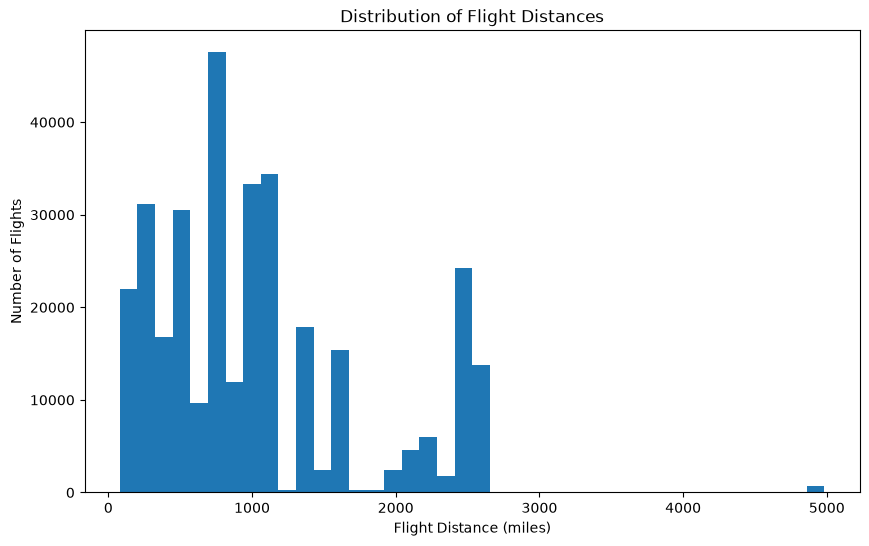

In [18]:
plt.figure(figsize=(10, 6))

plt.hist(analysis['distance'], bins=40)

plt.title('Distribution of Flight Distances')
plt.xlabel('Flight Distance (miles)')
plt.ylabel('Number of Flights')

plt.show()

## 2. Arrival Delays by Flight Distance

This section examines arrival delays to understand whether flights with different distances experience different average delays.

In [19]:
analysis['arr_delay'].mean()

np.float64(6.89537675731489)

In [20]:
analysis['arr_delay'].median()

np.float64(-5.0)

In [22]:
analysis['distance_group'] = pd.cut(
    analysis['distance'],
    bins=[0, 500, 1000, 1500, 2000, 5000],
    labels=['0-500', '501-1000', '1001-1500', '1501-2000', '2001+']
)

In [23]:
analysis.groupby('distance_group')['arr_delay'].mean()

distance_group
0-500        9.259420
501-1000     9.100965
1001-1500    5.615264
1501-2000    5.163489
2001+        1.312786
Name: arr_delay, dtype: float64

In [24]:
analysis.groupby('distance_group')['arr_delay'].count()

distance_group
0-500         76775
501-1000     105819
1001-1500     72798
1501-2000     20772
2001+         51182
Name: arr_delay, dtype: int64

In [25]:
analysis.groupby('distance_group')['arr_delay'].mean()

distance_group
0-500        9.259420
501-1000     9.100965
1001-1500    5.615264
1501-2000    5.163489
2001+        1.312786
Name: arr_delay, dtype: float64

In [27]:
analysis.groupby('distance_group')['arr_delay'].median()

distance_group
0-500       -5.0
501-1000    -4.0
1001-1500   -5.0
1501-2000   -5.0
2001+       -7.0
Name: arr_delay, dtype: float64

The median arrival delay was negative across all distance groups, indicating that the typical flight arrived ahead of schedule. However, the average arrival delay was positive across all groups. This difference suggests that some flights experienced larger delays, increasing the average. The longest-distance group had the lowest average delay and the earliest median arrival time.

In [28]:
analysis['arr_delay'].describe()

count    327346.000000
mean          6.895377
std          44.633292
min         -86.000000
25%         -17.000000
50%          -5.000000
75%          14.000000
max        1272.000000
Name: arr_delay, dtype: float64

### Additional Delay Statistics

The overall average arrival delay was approximately 6.9 minutes, while the median was -5 minutes. The maximum arrival delay was 1,272 minutes, indicating that some flights experienced extremely long delays. These unusually large delays may increase the overall average and help explain the difference between the mean and median.

In [29]:
analysis.groupby('distance_group')['arr_delay'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
distance_group,,,
0-500,76775,9.259420,-5.0
501-1000,105819,9.100965,-4.0
1001-1500,72798,5.615264,-5.0
1501-2000,20772,5.163489,-5.0
2001+,51182,1.312786,-7.0


### Summary of Arrival Delays by Flight Distance

The table below compares the number of flights, average arrival delay, and median arrival delay across five flight-distance groups.

## Conclusion

The analysis shows that average arrival delays tend to decrease as flight distance increases. Flights traveling up to 1,000 miles had the highest average arrival delays, while flights traveling more than 2,000 miles had the lowest.

However, the median arrival delay was negative across all distance groups, indicating that the typical flight arrived earlier than scheduled. The difference between the mean and median suggests that some flights with unusually large delays influenced the average results.

Overall, flight distance shows an association with arrival delays in this dataset, but it does not necessarily explain delays on its own.

## Data Preparation and Quality Notes

This analysis uses the cleaned flight dataset prepared by the group in the data cleaning notebook. The dataset contains 327,346 flights with valid arrival delay information.

The original flight data was merged with weather information using the origin airport and hourly timestamp. Flights with missing arrival delay values were excluded from the final analysis dataset.

For this distance analysis, no missing values were found in flight distance or arrival delay. Therefore, no additional cleaning was necessary for the variables used in this analysis.